# Bonus exercise: From banking queries to JSON

## Data

### Load and visualize data

In [1]:
# constants
INTENTS = (
"card_arrival",
"card_not_working",
"lost_or_stolen_card",
"pin_blocked",
"cancel_transfer",
"edit_personal_details",
"request_refund",
"terminate_account",
"transaction_charged_twice",
"exchange_rate"
)

RANDOM_SEED = 42

In [2]:
import pandas as pd

def load_and_filter_data(split="train", intents=INTENTS) -> pd.DataFrame:
  url = f"https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/refs/heads/master/banking_data/{split}.csv"
  data = pd.read_csv(url)
  filtered_data = data[data.category.isin(intents)]
  return filtered_data
  

In [3]:
data_train = load_and_filter_data()
data_test = load_and_filter_data("test")

In [4]:
print("Training data :")
display(data_train.head())
display(data_train.describe())
print("Test data:")
display(data_test.head())
display(data_test.describe())

Training data :


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


,text,category
count,1304,1304
unique,1304,10
top,I am still waiting on my card?,transaction_charged_twice
freq,1,175


Test data:


,text,category
0,How do I locate my card?,card_arrival
1,"I still have not received my new card, I order...",card_arrival
2,I ordered a card but it has not arrived. Help ...,card_arrival
3,Is there a way to know when my card will arrive?,card_arrival
4,My card has not arrived yet.,card_arrival


,text,category
count,400,400
unique,400,10
top,How do I locate my card?,card_arrival
freq,1,40


### Training and validation split

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_val = train_test_split(data_train, test_size=0.2, random_state=42)
print("X_train number of queries:")
print(X_train.count(), "\n")
print("X_val number of queries:")
print(X_val.count(), "\n")

X_train number of queries:
text        1043
category    1043
dtype: int64 

X_val number of queries:
text        261
category    261
dtype: int64 



## Loading from nanoGPT

In [81]:
#torch stuff
import torch
from accelerate import Accelerator

device = Accelerator().device
print(f"device: {device}")

device: mps


In [82]:
from nanoGPT.model import GPT
from transformers import AutoTokenizer
import torch

tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
model = GPT.from_pretrained("gpt2")
model.to(device)


loading weights from pretrained gpt: gpt2
forcing vocab_size=50257, block_size=1024, bias=True
number of parameters: 123.65M


GPT(
  (transformer): ModuleDict(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.0, inplace=False)
    (h): ModuleList(
      (0-11): 12 x Block(
        (ln_1): LayerNorm()
        (attn): CausalSelfAttention(
          (c_attn): Linear(in_features=768, out_features=2304, bias=True)
          (c_proj): Linear(in_features=768, out_features=768, bias=True)
          (attn_dropout): Dropout(p=0.0, inplace=False)
          (resid_dropout): Dropout(p=0.0, inplace=False)
        )
        (ln_2): LayerNorm()
        (mlp): MLP(
          (c_fc): Linear(in_features=768, out_features=3072, bias=True)
          (gelu): GELU(approximate='none')
          (c_proj): Linear(in_features=3072, out_features=768, bias=True)
          (dropout): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm()
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

## Training

In [10]:
%pip install -q peft

Note: you may need to restart the kernel to use updated packages.


In [139]:
from peft import LoraConfig, get_peft_model

# Unload the previous adapter if you rerun this setup cell.
if "sft_model" in globals():
    model = sft_model.unload()

torch.manual_seed(42)
lora_config = LoraConfig(
    r=64, # low rank for less complexity. with our small dataset -> less overfitting hopefully
    lora_dropout=0.1, # transformers regularize well by themselves so it's best practice to do zero dropout
    lora_alpha=128, # stabilize gradient 
    target_modules=[
      "c_attn", 
      "c_proj",
      "c_fc" # added this after testing because there was too little params with only the two first layers
    ], 
)

sft_model = get_peft_model(model, lora_config)
sft_model.print_trainable_parameters()
trainable = [p for p in sft_model.parameters() if p.requires_grad]
initial_adapter = [p.detach().clone() for p in trainable]
optimizer = torch.optim.AdamW(trainable, lr=2e-4)


def sft_batch(question, answer):
    full_text = [question, answer],
    batch = tokenizer(full_text, add_special_tokens=False,
                      return_tensors="pt").to(device)
    prompt_ids = tokenizer(question).input_ids
    assert batch.input_ids[0, :len(prompt_ids)].tolist() == prompt_ids
    batch["labels"] = batch.input_ids.clone()
    batch["labels"][:, :len(prompt_ids)] = -1
    return batch


def sft_update(question, answer):
    sft_model.train()
    optimizer.zero_grad(set_to_none=True)
    batch = sft_batch(question, answer)
    loss = sft_model(batch["input_ids"], batch["labels"])[1]
    if not torch.isfinite(loss):
        raise RuntimeError("Non-finite loss; reload the model before retrying.")
    loss.backward()
    torch.nn.utils.clip_grad_norm_(trainable, 1.0, error_if_nonfinite=True)
    optimizer.step()  # One parameter update.
    return loss.item()


loss = sft_update("How do I locate my card?",	'{"intent":"card_arrival"}')
print(f"Loss for the single update: {loss:.4f}")


trainable params: 9,437,184 || all params: 133,876,992 || trainable%: 7.0491
Loss for the single update: 10.0930


In [140]:
@torch.no_grad()
def generate_text_from_prompt(prompt, tokenizer, model, max_new_tokens=320,):
    """Generate a continuation; return only the newly generated text."""
    model.eval()
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    output_ids = model.generate(
        inputs["input_ids"],
        max_new_tokens=max_new_tokens)
    return tokenizer.decode(output_ids[0, inputs.input_ids.shape[1]:],
                            skip_special_tokens=True)


In [141]:
len(data_train)
from tqdm import tqdm

In [142]:
for question, answer in data_train.values:
  print(question, answer)
  break

I am still waiting on my card? card_arrival


In [98]:
for question, answer in tqdm(data_train.values):
    json_answer = '{"intent":"' + answer + '"}'
    print(json_answer)

100%|██████████| 1304/1304 [00:00<00:00, 250188.57it/s]

{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"card_arrival"}
{"intent":"c

In [86]:
question, answer = data_train.loc[0]
answer = '{"intent":"' + answer + '"}'
question, answer

('I am still waiting on my card?', '{"intent":"card_arrival"}')

In [143]:
import matplotlib.pyplot as plt

with torch.no_grad():
    for parameter, initial in zip(trainable, initial_adapter):
        parameter.copy_(initial)
optimizer = torch.optim.AdamW(trainable, lr=2e-4)


@torch.no_grad()
def check_responses():
    sft_model.eval()
    responses = []
    for text in tqdm(data_test["text"]):
      response = generate_text_from_prompt(
            text, tokenizer, sft_model, max_new_tokens=40
      )
      responses.append(response)
          
    return responses

#before = check_responses()
before = before
losses = []
for question, answer in tqdm(data_train.values):
    json_answer = '{"intent":"' + answer + '"}'
    losses.append(sft_update(question, json_answer))
after = check_responses()


100%|██████████| 400/400 [04:37<00:00,  1.44it/s]



PROMPT: How do I locate my card?
BEFORE: 


My button is displayed in the upper right corner of your card. If you're not in Atlanta it's not something to worry about though so be careful. If you find in-game files
AFTER:  Read more

0Product01010101010101010101010101010101010101010101010101010101010101010101

PROMPT: I still have not received my new card, I ordered over a week ago.
BEFORE:  $300.00 top euro money order is WRONG!!!!! REASON NO. variable. 25/50:............... Evas trade on weakness i never like to sit there and be sucked into a
AFTER:  I had a double double double double double double double double double double double double double double double double double double triple triple triple triple triple triple triple triple triple triple triple triple triple triple triple triple triple triple triple

PROMPT: I ordered a card but it has not arrived. Help please!
BEFORE:  Add Item

[ Grim NagaBackpack ]

Need help but have not received, please email help@grimnaga.comImage 

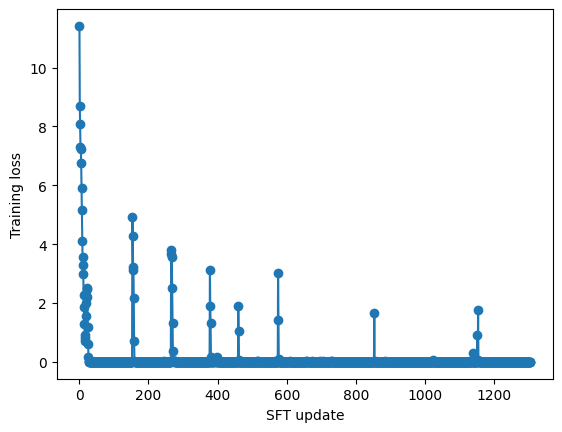

In [145]:
for question, original_response, updated_response in zip(data_test["text"], before, after):
    print(f"\nPROMPT: {question}\nBEFORE: {original_response}\nAFTER: {updated_response}")

plt.plot(range(1, len(data_train) + 1), losses, marker="o")
plt.xlabel("SFT update")
plt.ylabel("Training loss")
plt.show()